# CS680: Assignment 2


## Exercise 1.1

Simplify the expected loss in (2) as the usual least-squares regression (1), plus a familiar regularization function on w.

We have $\tilde{x}_i=x_i+\epsilon_i$, where
$\epsilon_i\sim\mathcal{N}(0,\lambda I)$.
The expectation is taken over $\epsilon_i$, treating $x_i$, $y_i$, and $w$ as fixed.

Expanding the square and using linearity of expectation gives

$$
\begin{aligned}
\mathbb{E}\left[(y_i-\langle w,\tilde{x}_i\rangle)^2\right]
&=
\mathbb{E}\left[
(y_i-\langle w,x_i\rangle-\langle w,\epsilon_i\rangle)^2
\right]\\
&=
(y_i-\langle w,x_i\rangle)^2\\
&\quad
-2(y_i-\langle w,x_i\rangle)
\mathbb{E}[\langle w,\epsilon_i\rangle]\\
&\quad
+\mathbb{E}[\langle w,\epsilon_i\rangle^2].
\end{aligned}
$$

Each noise component has mean zero, so the middle term vanishes:

$$
\mathbb{E}[\langle w,\epsilon_i\rangle]
=
\sum_{j=1}^{d}w_j\mathbb{E}[\epsilon_{ji}]
=
0.
$$

Each component also has variance $\lambda$. Since its mean is zero,
$\mathbb{E}[\epsilon_{ji}^2]=\lambda$.
For distinct components, independence and zero means give
$\mathbb{E}[\epsilon_{ji}\epsilon_{ki}]=0$ when $j\ne k$.
Therefore,

$$
\begin{aligned}
\mathbb{E}[\langle w,\epsilon_i\rangle^2]
&=
\sum_{j=1}^{d}w_j^2\mathbb{E}[\epsilon_{ji}^2]
+
2\sum_{1\le j<k\le d}
w_jw_k\mathbb{E}[\epsilon_{ji}\epsilon_{ki}]\\
&=
\lambda\sum_{j=1}^{d}w_j^2\\
&=
\lambda\lVert w\rVert_2^2.
\end{aligned}
$$

Substituting these results, the expected squared error for one example is

$$
\mathbb{E}\left[(y_i-\langle w,\tilde{x}_i\rangle)^2\right]
=
(y_i-\langle w,x_i\rangle)^2
+
\lambda\lVert w\rVert_2^2.
$$

Summing over all $n$ examples, problem (2) becomes

$$
\boxed{
\min_{w\in\mathbb{R}^{d}}
\sum_{i=1}^{n}(y_i-\langle w,x_i\rangle)^2
+
n\lambda\lVert w\rVert_2^2.
}
$$

Thus, additive Gaussian noise produces the usual least-squares objective
plus squared $L_2$ regularization (ridge regularization).
The factor $n$ appears because the same penalty
$\lambda\lVert w\rVert_2^2$ is added for each training example.

---

## Exercise 1.2

Simplify the expected loss in (2) as the usual least-squares regression (1), plus a familiar regularization function on w.

We have $\tilde{x}_i=x_i\odot\epsilon_i$, where
$p\epsilon_{ji}\sim\operatorname{Bernoulli}(p)$ independently across
coordinates. We assume $0<p\leq 1$, since the perturbation uses $1/p$.
The expectation is over the noise, with $x_i$, $y_i$, and $w$ fixed.

Each noise component satisfies

$$
\epsilon_{ji}=
\begin{cases}
0, & \text{with probability }1-p,\\
1/p, & \text{with probability }p.
\end{cases}
$$

Therefore,

$$
\mathbb{E}[\epsilon_{ji}]
=
(1-p)\cdot 0+p\cdot\frac{1}{p}
=
1,
\qquad
\mathbb{E}[\epsilon_{ji}^2]
=
(1-p)\cdot 0+p\cdot\frac{1}{p^2}
=
\frac{1}{p}.
$$

It follows that

$$
\mathbb{E}[\epsilon_{ji}-1]=0,
$$

and

$$
\begin{aligned}
\mathbb{E}[(\epsilon_{ji}-1)^2]
&=
\mathbb{E}[\epsilon_{ji}^2]
-2\mathbb{E}[\epsilon_{ji}]+1\\
&=
\frac{1}{p}-2+1\\
&=
\frac{1-p}{p}.
\end{aligned}
$$

For $j\neq k$, independence gives

$$
\mathbb{E}[(\epsilon_{ji}-1)(\epsilon_{ki}-1)]
=
\mathbb{E}[\epsilon_{ji}-1]\,
\mathbb{E}[\epsilon_{ki}-1]
=
0.
$$

We can write the perturbed prediction as

$$
\langle w,\tilde{x}_i\rangle
=
\sum_{j=1}^{d}w_jx_{ji}\epsilon_{ji}
=
\langle w,x_i\rangle
+
\sum_{j=1}^{d}w_jx_{ji}(\epsilon_{ji}-1).
$$

Expanding the squared error and taking expectations,

$$
\begin{aligned}
\mathbb{E}[(y_i-\langle w,\tilde{x}_i\rangle)^2]
&=
(y_i-\langle w,x_i\rangle)^2\\
&\quad
-2(y_i-\langle w,x_i\rangle)
\sum_{j=1}^{d}w_jx_{ji}\mathbb{E}[\epsilon_{ji}-1]\\
&\quad
+\mathbb{E}\left[
\left(\sum_{j=1}^{d}w_jx_{ji}(\epsilon_{ji}-1)\right)^2
\right].
\end{aligned}
$$

The middle term is zero. Expanding the last square, the products
between distinct coordinates also have expectation zero. Thus,

$$
\begin{aligned}
\mathbb{E}\left[
\left(\sum_{j=1}^{d}w_jx_{ji}(\epsilon_{ji}-1)\right)^2
\right]
&=
\sum_{j=1}^{d}w_j^2x_{ji}^2
\mathbb{E}[(\epsilon_{ji}-1)^2]\\
&=
\frac{1-p}{p}\sum_{j=1}^{d}w_j^2x_{ji}^2.
\end{aligned}
$$

Therefore, for each example,

$$
\mathbb{E}[(y_i-\langle w,\tilde{x}_i\rangle)^2]
=
(y_i-\langle w,x_i\rangle)^2
+
\frac{1-p}{p}\sum_{j=1}^{d}w_j^2x_{ji}^2.
$$

Summing over all $n$ examples, problem (2) becomes

$$
\boxed{
\min_{w\in\mathbb{R}^{d}}
\sum_{i=1}^{n}(y_i-\langle w,x_i\rangle)^2
+
\frac{1-p}{p}
\sum_{j=1}^{d}
\left(\sum_{i=1}^{n}x_{ji}^2\right)w_j^2.
}
$$

This is the usual least-squares objective plus a weighted squared
$L_2$ penalty. Unlike part (a), the penalty on each weight $w_j$
depends on the sum of squared values of its corresponding feature.

When $p=1$, no features are removed, and the regularization term
vanishes.

---

## Exercise 1.3

Find a regularized problem (that only involves {(xi, yi)}) that is equivalent to the expected loss.

We have $\tilde{x}_i=x_i+\epsilon_i$, where
$\epsilon_i\sim\mathcal{N}(0,\lambda I)$ and $y_i\in\{-1,+1\}$.
The expectation is over $\epsilon_i$, treating $x_i$, $y_i$, and $w$ as fixed.

Using linearity of the inner product and the identity
$\exp(a+b)=\exp(a)\exp(b)$, we obtain

$$
\begin{aligned}
\mathbb{E}\left[\exp(-y_i\langle w,\tilde{x}_i\rangle)\right]
&=
\mathbb{E}\left[
\exp(-y_i\langle w,x_i\rangle-y_i\langle w,\epsilon_i\rangle)
\right]\\
&=
\exp(-y_i\langle w,x_i\rangle)
\mathbb{E}\left[\exp(-y_i\langle w,\epsilon_i\rangle)\right].
\end{aligned}
$$

Since the noise components are independent Gaussians with mean zero and
variance $\lambda$, their linear combination satisfies

$$
\langle w,\epsilon_i\rangle
=
\sum_{j=1}^{d}w_j\epsilon_{ji}
\sim
\mathcal{N}\left(0,\lambda\sum_{j=1}^{d}w_j^2\right)
=
\mathcal{N}(0,\lambda\lVert w\rVert_2^2).
$$

Thus, $-y_i\langle w,\epsilon_i\rangle$ has the same distribution as $aZ$,
where $Z\sim\mathcal{N}(0,1)$ and
$a=-y_i\sqrt{\lambda}\lVert w\rVert_2$.

We compute the required expectation by completing the square:

$$
az-\frac{z^2}{2}
=
-\frac{(z-a)^2}{2}+\frac{a^2}{2}.
$$

Therefore,

$$
\begin{aligned}
\mathbb{E}[\exp(aZ)]
&=
\frac{1}{\sqrt{2\pi}}
\int_{-\infty}^{\infty}
\exp\left(az-\frac{z^2}{2}\right)\,dz\\
&=
\exp\left(\frac{a^2}{2}\right)
\frac{1}{\sqrt{2\pi}}
\int_{-\infty}^{\infty}
\exp\left(-\frac{(z-a)^2}{2}\right)\,dz\\
&=
\exp\left(\frac{a^2}{2}\right).
\end{aligned}
$$

The normalized integral equals $1$ because it integrates the density
of $\mathcal{N}(a,1)$. Since $y_i^2=1$, we have
$a^2=\lambda\lVert w\rVert_2^2$. Consequently,

$$
\mathbb{E}\left[\exp(-y_i\langle w,\epsilon_i\rangle)\right]
=
\exp\left(\frac{\lambda}{2}\lVert w\rVert_2^2\right).
$$

Substituting into the expected loss and summing over the examples gives

$$
\begin{aligned}
\sum_{i=1}^{n}
\mathbb{E}\left[\exp(-y_i\langle w,\tilde{x}_i\rangle)\right]
&=
\sum_{i=1}^{n}
\exp(-y_i\langle w,x_i\rangle)
\exp\left(\frac{\lambda}{2}\lVert w\rVert_2^2\right)\\
&=
\exp\left(\frac{\lambda}{2}\lVert w\rVert_2^2\right)
\sum_{i=1}^{n}\exp(-y_i\langle w,x_i\rangle).
\end{aligned}
$$

This objective is strictly positive. Since the logarithm is strictly
increasing, taking its logarithm preserves the minimizers.
Therefore, an equivalent regularized problem is

$$
\boxed{
\min_{w\in\mathbb{R}^{d}}
\log\left(
\sum_{i=1}^{n}\exp(-y_i\langle w,x_i\rangle)
\right)
+
\frac{\lambda}{2}\lVert w\rVert_2^2.
}
$$

This problem only involves the original training data and adds squared
$L_2$ regularization to the logarithm of the exponential-loss sum.
The logarithmic objective has the same minimizers as the expected loss,
but not the same objective values.

---

## Exercise 2.1



Implement and train the exact VGG11 architecture specified in the assignment on MNIST, resizing images from 28×28 to 32×32 and using `torch.nn.CrossEntropyLoss`.

All numerical results below will be generated by running this notebook. We do not use test metrics to select hyperparameters or choose the best epoch. The assignment requests per-epoch test curves; configurations and epoch count are fixed before those results are viewed.

### 1. Imports, reproducibility, and device

In [4]:
import platform
import random

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import MNIST

SEED = 480
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Device:", device)


Python: 3.12.12
PyTorch: 2.5.1
torchvision: 0.20.1
Matplotlib: 3.11.1
Device: mps


### 2. Dataset and data loaders

The resizing is done **before** converting to a tensor. We use a single grayscale channel and do not introduce optional normalization. `USE_SMALL_TRAIN_SET` is an assignment-authorized fallback for slow computers. Keep it `False` for the full dataset; if set to `True`, explicitly report the subset and fixed selection in the submission.

In [5]:
BATCH_SIZE = 64
NUM_EPOCHS = 3
LEARNING_RATE = 0.001
USE_SMALL_TRAIN_SET = False  # Set True only if full training is infeasible.

transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
])

train_dataset = MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = MNIST(root="./data", train=False, download=True, transform=transform)

if USE_SMALL_TRAIN_SET:
    # Reproducible subset of 6,000 training examples (one tenth).
    generator = torch.Generator().manual_seed(SEED)
    indices = torch.randperm(len(train_dataset), generator=generator)[:6000].tolist()
    train_dataset = Subset(train_dataset, indices)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
# Separate non-shuffled loader for consistent training metrics in eval mode.
train_eval_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels = next(iter(train_loader))
assert tuple(images.shape[1:]) == (1, 32, 32)
print("Training examples:", len(train_dataset))
print("Test examples:", len(test_dataset))
print("First batch:", tuple(images.shape), tuple(labels.shape))

Training examples: 60000
Test examples: 10000
First batch: (64, 1, 32, 32) (64,)


### 3. VGG11 implementation

The layer order and sizes below match the professor’s list exactly: eight convolutions (each with BatchNorm and ReLU), five MaxPool layers, then `FC(512,4096)`, `FC(4096,4096)`, and `FC(4096,10)`. No pretrained weights are used.

In [7]:
class VGG11MNIST(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(256, 512, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(inplace=True),
            nn.Conv2d(512, 512, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(512), nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512, 4096), nn.ReLU(inplace=True), nn.Dropout(p=0.5),
            nn.Linear(4096, 4096), nn.ReLU(inplace=True), nn.Dropout(p=0.5),
            nn.Linear(4096, 10),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        return self.classifier(x)


model = VGG11MNIST().to(device)

# Verify the spatial dimensions before training.
with torch.no_grad():
    dummy = torch.zeros(2, 1, 32, 32, device=device)
    feature_output = model.features(dummy)
    logits = model(dummy)
assert tuple(feature_output.shape) == (2, 512, 1, 1), feature_output.shape
assert tuple(logits.shape) == (2, 10), logits.shape
print("Features:", tuple(feature_output.shape))
print("Logits:", tuple(logits.shape))

Features: (2, 512, 1, 1)
Logits: (2, 10)


#### Tensor dimensions

The 3×3 convolutions with stride 1 and padding 1 preserve height and width. Each 2×2 max-pool with stride 2 halves them:

| Stage | Spatial dimensions | Channels |
|---|---|---|
| Input | 32×32 | 1 |
| Pool 1 | 16×16 | 64 |
| Pool 2 | 8×8 | 128 |
| Pool 3 | 4×4 | 256 |
| Pool 4 | 2×2 | 512 |
| Pool 5 | 1×1 | 512 |

Therefore, the final tensor contains `512 × 1 × 1 = 512` features per example, matching `FC(512, 4096)`. With the original 28×28 inputs, five successive halvings would not produce the required 1×1 feature map; the assignment explicitly requires resizing.

### 4. Training and evaluation functions

Metrics are computed by aggregating the total loss and number of correct predictions over all examples. Training-set curves are evaluated **after each epoch in evaluation mode** so BatchNorm and Dropout behave consistently in both train/test measurements.

In [8]:
def train_one_epoch(
        model: nn.Module,
        loader: DataLoader,
        optimizer: torch.optim.Optimizer,
        criterion: nn.Module,
        device: torch.device,
) -> None:
    model.train()
    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()


@torch.no_grad()
def evaluate(
        model: nn.Module,
        loader: DataLoader,
        criterion: nn.Module,
        device: torch.device,
) -> tuple[float, float]:
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)
        logits = model(images)
        batch_loss = criterion(logits, labels)
        batch_size = labels.size(0)

        total_loss += batch_loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    if total_examples == 0:
        raise ValueError("Cannot evaluate an empty data loader.")
    return total_loss / total_examples, 100.0 * total_correct / total_examples


### 5. Train for the predetermined number of epochs

`CrossEntropyLoss` uses raw output logits and integer class labels; do not add Softmax to the last layer. This model is large, so the full dataset can be slow on CPU/MPS. **Do not choose a best epoch or change hyperparameters based on the test curves.**

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

history = {
    "epoch": [],
    "train_accuracy": [],
    "test_accuracy": [],
    "train_loss": [],
    "test_loss": [],
}

for epoch in range(1, NUM_EPOCHS + 1):
    train_one_epoch(model, train_loader, optimizer, criterion, device)

    train_loss, train_acc = evaluate(model, train_eval_loader, criterion, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, device)

    history["epoch"].append(epoch)
    history["train_accuracy"].append(train_acc)
    history["test_accuracy"].append(test_acc)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)

    print(
        f"Epoch {epoch}/{NUM_EPOCHS} | "
        f"train acc: {train_acc:.2f}% | test acc: {test_acc:.2f}% | "
        f"train loss: {train_loss:.4f} | test loss: {test_loss:.4f}",
        flush=True,
    )

Epoch 1/3 | train acc: 93.88% | test acc: 94.25% | train loss: 0.2172 | test loss: 0.2042
Epoch 2/3 | train acc: 98.17% | test acc: 98.23% | train loss: 0.0747 | test loss: 0.0763
Epoch 3/3 | train acc: 97.02% | test acc: 97.09% | train loss: 0.1233 | test loss: 0.1328


In [18]:
from pathlib import Path

# Save the final baseline model after all training epochs.
weights_path = Path("vgg11_mnist_baseline.pt")
torch.save(model.state_dict(), weights_path)

print(f"Weights saved to: {weights_path.resolve()}")

Weights saved to: /Users/carlospineda/PycharmProjects/uw-f26/CS680/assignments/a2/vgg11_mnist_baseline.pt


## Exercise 2.2

(a) test accuracy, (b) training accuracy, (c) test loss, (d) training loss versus epoch.

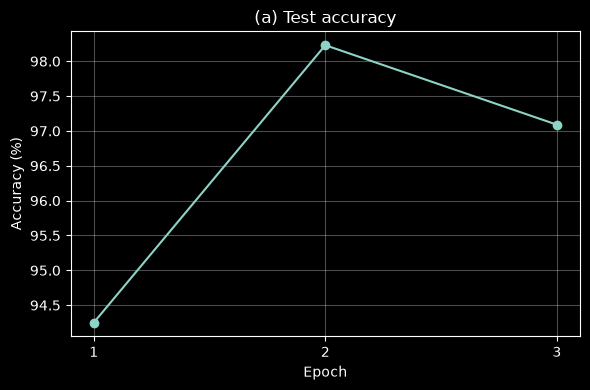

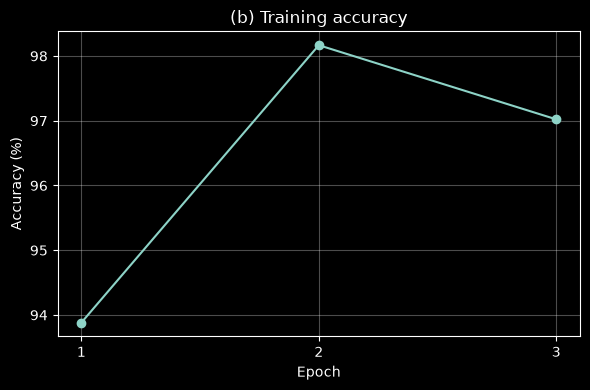

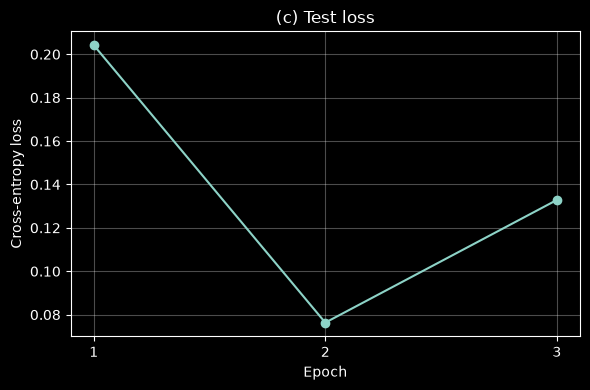

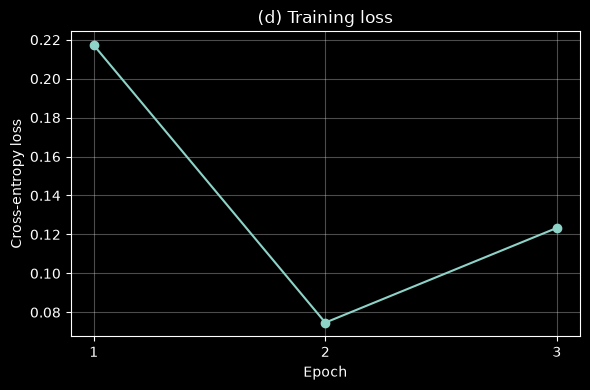

In [13]:
def plot_metric(
        epochs: list[int],
        values: list[float],
        title: str,
        ylabel: str,
) -> None:
    if not epochs or len(epochs) != len(values):
        raise ValueError("Epochs and metric values must be nonempty and aligned.")
    plt.figure(figsize=(6, 4))
    plt.plot(epochs, values, marker="o")
    plt.xticks(epochs)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_metric(history["epoch"], history["test_accuracy"], "(a) Test accuracy", "Accuracy (%)")
plot_metric(history["epoch"], history["train_accuracy"], "(b) Training accuracy", "Accuracy (%)")
plot_metric(history["epoch"], history["test_loss"], "(c) Test loss", "Cross-entropy loss")
plot_metric(history["epoch"], history["train_loss"], "(d) Training loss", "Cross-entropy loss")

### Results for the report

After three predetermined training epochs, the final model achieved:

- Final training accuracy: **97.02%**
- Final test accuracy: **97.09%**
- Final training loss: **0.1233**
- Final test loss: **0.1328**

**Method:** VGG11 as specified in the assignment, MNIST resized to
32×32, CrossEntropyLoss, Adam (learning rate `0.001`), batch size `64`,
three predetermined epochs, and random seed `480`.

**Interpretation:** Training and test accuracy increased from epoch 1
to epoch 2, while both losses decreased. In epoch 3, accuracy decreased
and loss increased on both sets, although the final results remained
better than those of epoch 1.

Training and test metrics remained close throughout the experiment,
with no large gap between their performance. The simultaneous
deterioration on both sets in epoch 3 does not, by itself, demonstrate
overfitting. These results alone do not establish the cause of that
deterioration.

We report the model after the third, predetermined epoch rather than
selecting the epoch with the highest test accuracy.

## Exercise 2.3

Report the test accuracy after each flip. What is the effect?

Report the test accuracy after adding Gaussian noise. What is the effect?

### Test accuracy function

In [14]:
import math
import torch
from torchvision import transforms


@torch.no_grad()
def accuracy_with_transform(transform) -> float:
    model.eval()
    correct = 0
    total = 0

    for images, labels in test_loader:
        # Apply the perturbation to the original test batch.
        images = transform(images).to(device)
        labels = labels.to(device)

        predictions = model(images).argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    if total == 0:
        raise ValueError("The test loader is empty.")

    return 100.0 * correct / total

### 2.3(e): Horizontal and vertical flips

Evaluate each flip separately, applying it to every test image.

In [15]:
# Evaluate horizontal flips.
horizontal_accuracy = accuracy_with_transform(
    transforms.RandomHorizontalFlip(p=1)
)
print(f"Horizontal flip test accuracy: {horizontal_accuracy:.2f}%")

# Evaluate vertical flips independently.
vertical_accuracy = accuracy_with_transform(
    transforms.RandomVerticalFlip(p=1)
)
print(f"Vertical flip test accuracy: {vertical_accuracy:.2f}%")

Horizontal flip test accuracy: 38.10%
Vertical flip test accuracy: 38.34%


### 2.3(f): Gaussian noise

Evaluate variances 0.01, 0.1, and 1 separately. Noise is added after resizing and `ToTensor()`, without clipping pixel values.


In [16]:
# Fix the random seed for this noise experiment.
torch.manual_seed(480)

noise_accuracies = {}

for variance in [0.01, 0.1, 1.0]:
    noise_transform = transforms.Lambda(
        lambda x, variance=variance:
        x + math.sqrt(variance) * torch.randn_like(x)
    )

    accuracy = accuracy_with_transform(noise_transform)
    noise_accuracies[variance] = accuracy

    print(
        f"Gaussian noise variance {variance:g} "
        f"| Test accuracy: {accuracy:.2f}%"
    )

Gaussian noise variance 0.01 | Test accuracy: 95.64%
Gaussian noise variance 0.1 | Test accuracy: 60.16%
Gaussian noise variance 1 | Test accuracy: 19.30%


### Exercise 2.3(e): Flipped test images

We evaluated the final trained model with each flip applied separately
to all test images, without retraining. The original test accuracy
was **97.09%**.

| Transformation | Test accuracy |
|---|---:|
| Horizontal flip | 38.10% |
| Vertical flip | 38.34% |

**Effect:** Both flips substantially reduced test accuracy. Horizontal
flipping caused a decrease of **58.99 percentage points**, while
vertical flipping caused a decrease of **58.75 percentage points**
compared with the original test accuracy.

These results show that the model is sensitive to the orientation of
the digits and generalizes poorly to these flipped images. Although
it performs well on the original test set, it does not reliably
recognize the same digits after reflection. Both transformations had
a similar effect.

Flipping also does not necessarily preserve the visual identity of
a handwritten digit. Because the evaluation keeps the original
labels, some flipped images may become ambiguous or no longer
resemble their original class.

### Exercise 2.3(f): Gaussian noise

We added zero-mean Gaussian noise to the resized test tensors, using
the square root of each specified variance as the noise standard
deviation. Values were not clipped after adding noise. The model
was evaluated without retraining.

| Noise variance |                       Test accuracy |
|---|------------------------------------:|
| 0.01 |                             95.64%% |
| 0.1 |                              60.16% |
| 1 |                                   19.30% |

**Effect:** Test accuracy decreased as the noise variance increased.
With variance **0.01**, accuracy was **95.64%**, only **1.45 percentage
points** below the original accuracy of **97.09%**. However, accuracy
fell to **60.16%** with variance **0.1** and to **19.30%** with
variance **1**, corresponding to decreases of **36.93** and **77.79
percentage points**, respectively.

These results indicate that the model retains most of its performance
under the smallest tested noise level but is much less robust to
stronger perturbations. Although it generalizes well to the original
test images, its predictions become substantially less reliable when
the inputs are heavily corrupted. Good performance on clean test data
therefore does not imply robustness to these noisy inputs.

## Exercise 2.4

Report the test accuracy and explain what kind of data augmentation you use in retraining.

In [19]:
# 1. Prepare augmented training images and retrain a separate model.
aug_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.RandomAffine(
        degrees=10, translate=(0.1, 0.1),
        interpolation=transforms.InterpolationMode.BILINEAR, fill=0,
    ),
    transforms.ToTensor(),
])
aug_train_dataset = MNIST(
    root="./data", train=True, download=False, transform=aug_transform
)
if isinstance(train_dataset, Subset):
    aug_train_dataset = Subset(aug_train_dataset, train_dataset.indices)

aug_train_loader = DataLoader(
    aug_train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

model_aug = VGG11MNIST().to(device)
criterion_aug = nn.CrossEntropyLoss()
optimizer_aug = torch.optim.Adam(model_aug.parameters(), lr=LEARNING_RATE)

for epoch in range(1, NUM_EPOCHS + 1):
    train_one_epoch(
        model_aug, aug_train_loader, optimizer_aug, criterion_aug, device
    )
    print(f"Epoch {epoch}/{NUM_EPOCHS} completed.", flush=True)

# Preserve the baseline model and checkpoint.
torch.save(model_aug.state_dict(), "vgg11_mnist_augmented.pt")

Epoch 1/3 completed.
Epoch 2/3 completed.
Epoch 3/3 completed.


In [20]:
# 2. Print the five test accuracies for the augmented model.
import math


@torch.no_grad()
def augmented_test_accuracy(transform) -> float:
    model_aug.eval()
    correct, total = 0, 0

    for images, labels in test_loader:
        images = transform(images).to(device)
        labels = labels.to(device)
        predictions = model_aug(images).argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    if total == 0:
        raise ValueError("The test loader is empty.")
    return 100.0 * correct / total


for name, flip in [
    ("Horizontal flip", transforms.RandomHorizontalFlip(p=1)),
    ("Vertical flip", transforms.RandomVerticalFlip(p=1)),
]:
    accuracy = augmented_test_accuracy(flip)
    print(f"{name}: {accuracy:.2f}%", flush=True)

# Use the same noise convention as Exercise 2.3; do not clip values.
torch.manual_seed(SEED)
for variance in [0.01, 0.1, 1.0]:
    noise = transforms.Lambda(
        lambda x, variance=variance:
        x + math.sqrt(variance) * torch.randn_like(x)
    )
    accuracy = augmented_test_accuracy(noise)
    print(f"Gaussian noise (variance {variance:g}): {accuracy:.2f}%", flush=True)

Horizontal flip: 40.28%
Vertical flip: 41.39%
Gaussian noise (variance 0.01): 91.89%
Gaussian noise (variance 0.1): 31.02%
Gaussian noise (variance 1): 10.11%


For retraining, we applied random rotations between −10° and +10° and random horizontal and vertical translations of up to 10% of the image dimensions. These transformations were applied only to the training images to introduce small variations in digit orientation and position.

After retraining, we evaluated the model under the same five test conditions used in Exercise 2.3, applying each perturbation separately.

| Test condition | Test accuracy |
|---|--------------:|
| Horizontal flip |        40.28% |
| Vertical flip |        41.39% |
| Gaussian noise, variance 0.01 |        91.89% |
| Gaussian noise, variance 0.1 |        31.02% |
| Gaussian noise, variance 1 |        10.11% |